<a href="https://colab.research.google.com/github/parimigowtham1432-stack/ML-TASK-K-means-case-study-submission/blob/main/TASK%205.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NEW DATASET GENERATED SUCCESSFULLY!
Total Records: 500
Total Columns: 5


,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,70,Male,26,31.78,74
1,30,Male,20,26.52,92
2,472,Female,20,83.90,95
3,345,Female,50,73.85,12
4,55,Male,30,21.64,77
5,190,Male,33,37.27,47
6,464,Male,28,85.62,93
7,185,Female,37,49.85,56
8,141,Female,37,48.05,57
9,126,Male,37,38.22,46



DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      500 non-null    int64  
 1   Gender          500 non-null    object 
 2   Age             500 non-null    int64  
 3   Annual_Income   500 non-null    float64
 4   Spending_Score  500 non-null    int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 19.7+ KB

MISSING VALUES
CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64

DUPLICATE RECORDS: 0

STATISTICAL SUMMARY


,CustomerID,Age,Annual_Income,Spending_Score
count,500.000000,500.000000,500.000000,500.000000
mean,250.500000,36.648000,55.428240,51.330000
std,144.481833,10.489431,28.236551,27.678101
min,1.000000,18.000000,5.000000,4.000000
25%,125.750000,28.000000,29.390000,24.750000
50%,250.500000,35.000000,50.050000,49.000000
75%,375.250000,45.000000,84.732500,79.000000
max,500.000000,62.000000,105.960000,100.000000


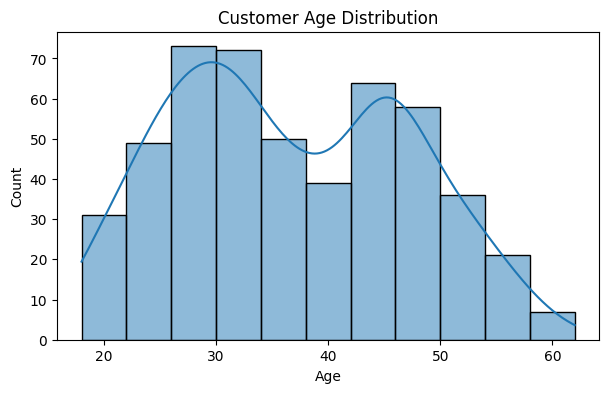

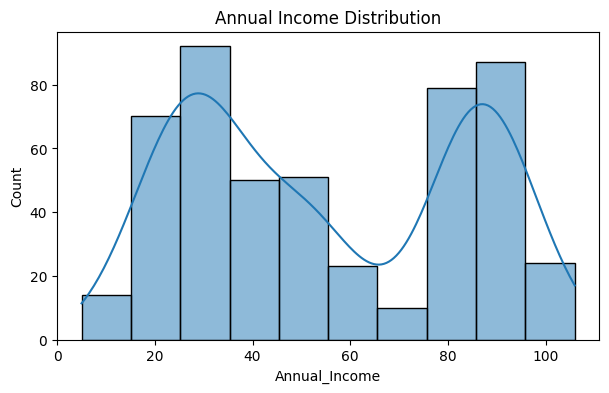

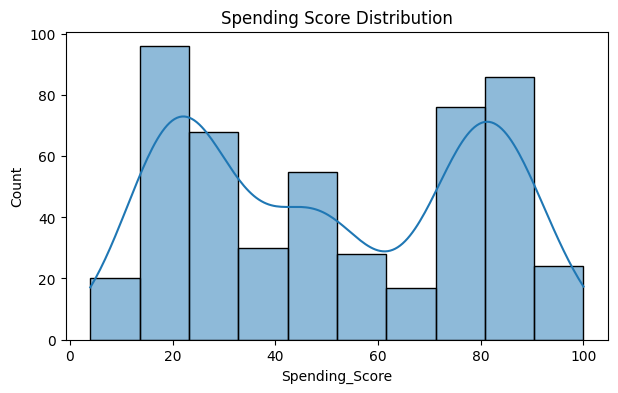

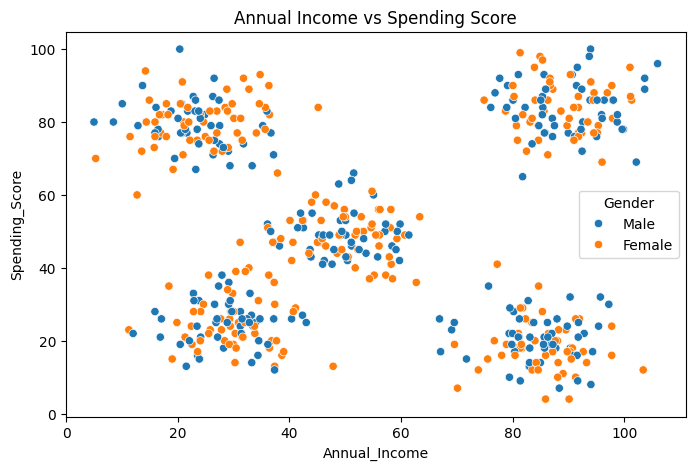


STEP 1 AND STEP 2 COMPLETED!


In [2]:

# ==========================================
# CUSTOMER SEGMENTATION USING K-MEANS
# STEP 1: GENERATE NEW DATASET
# STEP 2: PERFORM EDA
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate dataset
np.random.seed(100)

groups = [
    (100, 25, 25, 80),
    (100, 35, 50, 50),
    (100, 45, 30, 25),
    (100, 50, 85, 20),
    (100, 30, 90, 85)
]

data = []
customer_id = 1

for count, age, income, spending in groups:
    for _ in range(count):
        data.append([
            customer_id,
            np.random.choice(["Male", "Female"]),
            max(18, int(np.random.normal(age, 5))),
            round(max(5, np.random.normal(income, 7)), 2),
            int(np.clip(np.random.normal(spending, 7), 1, 100))
        ])
        customer_id += 1

# Create DataFrame
df = pd.DataFrame(data, columns=[
    "CustomerID",
    "Gender",
    "Age",
    "Annual_Income",
    "Spending_Score"
])

# Shuffle dataset
df = df.sample(frac=1, random_state=100).reset_index(drop=True)

# Save dataset
df.to_csv("/content/customer_dataset.csv", index=False)

print("NEW DATASET GENERATED SUCCESSFULLY!")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

# Display records
display(df.head(10))

# Dataset information
print("\nDATASET INFORMATION")
df.info()

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS:", df.duplicated().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

# Age distribution
plt.figure(figsize=(7,4))
sns.histplot(df["Age"], kde=True)
plt.title("Customer Age Distribution")
plt.show()

# Income distribution
plt.figure(figsize=(7,4))
sns.histplot(df["Annual_Income"], kde=True)
plt.title("Annual Income Distribution")
plt.show()

# Spending distribution
plt.figure(figsize=(7,4))
sns.histplot(df["Spending_Score"], kde=True)
plt.title("Spending Score Distribution")
plt.show()

# Income vs Spending
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Gender"
)
plt.title("Annual Income vs Spending Score")
plt.show()

print("\nSTEP 1 AND STEP 2 COMPLETED!")


In [3]:

# STEP 3: DATA PREPROCESSING

import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("/content/customer_dataset.csv")

# Select features for clustering
X = df[["Annual_Income", "Spending_Score"]]

print("Selected Features:")
display(X.head())

# Initialize StandardScaler
scaler = StandardScaler()

# Apply feature scaling
X_scaled = scaler.fit_transform(X)

# Convert scaled data into DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Annual_Income", "Spending_Score"]
)

print("\nScaled Dataset:")
display(X_scaled_df.head())

# Check dimensions
print("\nOriginal Data Shape:", X.shape)
print("Scaled Data Shape:", X_scaled.shape)

print("\nDATA PREPROCESSING COMPLETED!")


Selected Features:


,Annual_Income,Spending_Score
0,31.78,74
1,26.52,92
2,83.90,95
3,73.85,12
4,21.64,77



Scaled Dataset:


,Annual_Income,Spending_Score
0,-0.838343,0.819879
1,-1.024813,1.470864
2,1.009340,1.579362
3,0.653062,-1.422402
4,-1.197812,0.928377



Original Data Shape: (500, 2)
Scaled Data Shape: (500, 2)

DATA PREPROCESSING COMPLETED!


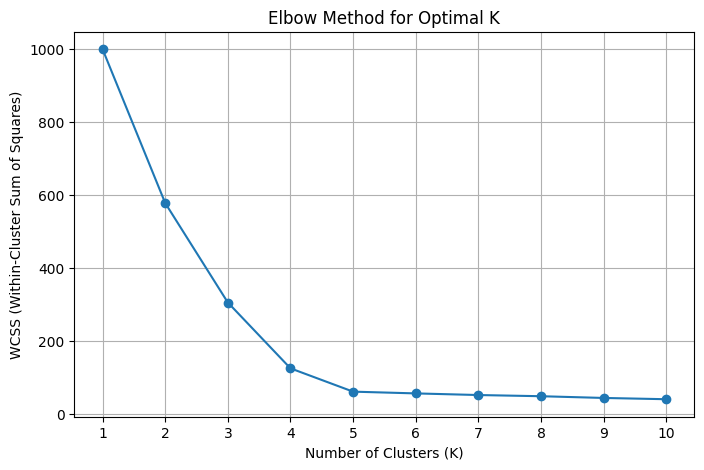

WCSS Values:
K = 1: 1000.00
K = 2: 577.79
K = 3: 304.81
K = 4: 124.13
K = 5: 60.14
K = 6: 55.33
K = 7: 50.86
K = 8: 47.60
K = 9: 42.86
K = 10: 39.36


In [4]:

# STEP 4: ELBOW METHOD

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store WCSS values
wcss = []

# Test different numbers of clusters
for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

# Plot Elbow Graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

print("WCSS Values:")
for k, value in enumerate(wcss, start=1):
    print(f"K = {k}: {value:.2f}")


CUSTOMER CLUSTER ASSIGNMENTS


,CustomerID,Gender,Age,Annual_Income,Spending_Score,Cluster
0,70,Male,26,31.78,74,0
1,30,Male,20,26.52,92,0
2,472,Female,20,83.90,95,1
3,345,Female,50,73.85,12,2
4,55,Male,30,21.64,77,0
5,190,Male,33,37.27,47,4
6,464,Male,28,85.62,93,1
7,185,Female,37,49.85,56,4
8,141,Female,37,48.05,57,4
9,126,Male,37,38.22,46,4



CUSTOMER COUNT IN EACH CLUSTER
Cluster
0    101
1    100
2    100
3    101
4     98
Name: count, dtype: int64


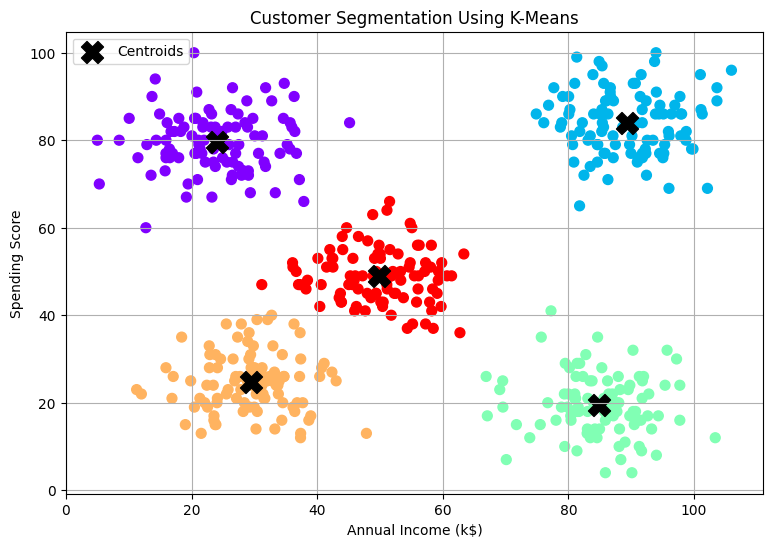


K-MEANS MODEL TRAINED SUCCESSFULLY!
Clustered dataset saved successfully!


In [5]:

# STEP 5: TRAIN K-MEANS MODEL

from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

# Select optimal number of clusters
kmeans = KMeans(
    n_clusters=5,
    init="k-means++",
    random_state=42,
    n_init=10
)

# Train the model and predict clusters
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Display customer cluster assignments
print("CUSTOMER CLUSTER ASSIGNMENTS")
display(df.head(10))

# Count customers in each cluster
print("\nCUSTOMER COUNT IN EACH CLUSTER")
print(df["Cluster"].value_counts().sort_index())

# Get cluster centers in original units
centers = scaler.inverse_transform(kmeans.cluster_centers_)

# Plot clusters
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap="rainbow",
    s=50
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend()
plt.grid(True)
plt.show()

# Save clustered dataset
df.to_csv("/content/clustered_customers.csv", index=False)

print("\nK-MEANS MODEL TRAINED SUCCESSFULLY!")
print("Clustered dataset saved successfully!")


In [6]:

# STEP 6: MODEL EVALUATION

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Calculate evaluation metrics
silhouette = silhouette_score(X_scaled, df["Cluster"])

davies = davies_bouldin_score(
    X_scaled,
    df["Cluster"]
)

calinski = calinski_harabasz_score(
    X_scaled,
    df["Cluster"]
)

# Display results
print("K-MEANS MODEL EVALUATION")
print("--------------------------------")

print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(davies, 4))
print("Calinski-Harabasz Score:", round(calinski, 4))

# Save evaluation results
results = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score"
    ],
    "Value": [
        silhouette,
        davies,
        calinski
    ]
})

results.to_csv("/content/evaluation_results.csv", index=False)

print("\nEvaluation results saved successfully!")
display(results)


K-MEANS MODEL EVALUATION
--------------------------------
Silhouette Score: 0.6853
Davies-Bouldin Index: 0.4293
Calinski-Harabasz Score: 1933.8343

Evaluation results saved successfully!


,Metric,Value
0,Silhouette Score,0.685286
1,Davies-Bouldin Index,0.429321
2,Calinski-Harabasz Score,1933.834257


CUSTOMER CLUSTER PROFILES


,Customer_Count,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,101,25.16,23.98,79.49
1,100,29.12,89.41,83.97
2,100,49.57,84.88,19.51
3,101,44.63,29.48,24.70
4,98,34.76,49.86,48.92


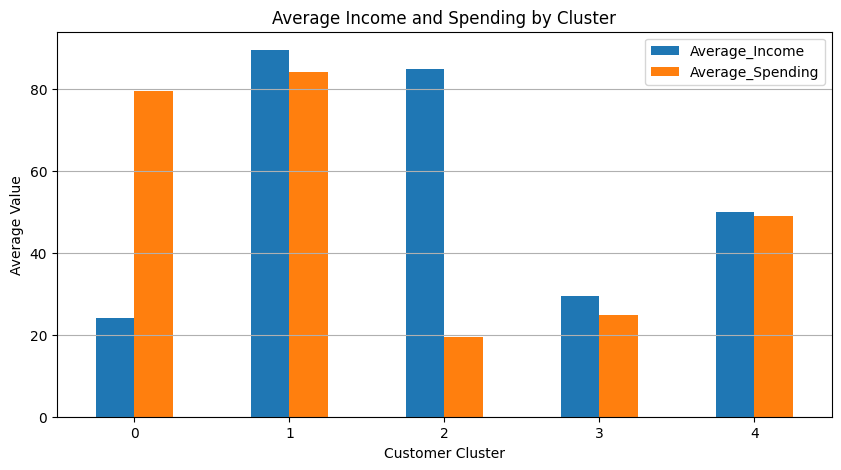

Cluster analysis saved successfully!


In [7]:

# STEP 7: CUSTOMER CLUSTER ANALYSIS

# Calculate average values for each cluster
cluster_analysis = df.groupby("Cluster").agg({
    "CustomerID": "count",
    "Age": "mean",
    "Annual_Income": "mean",
    "Spending_Score": "mean"
}).round(2)

# Rename columns
cluster_analysis.columns = [
    "Customer_Count",
    "Average_Age",
    "Average_Income",
    "Average_Spending"
]

print("CUSTOMER CLUSTER PROFILES")
display(cluster_analysis)

# Visualize cluster profiles
cluster_analysis[[
    "Average_Income",
    "Average_Spending"
]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Income and Spending by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.show()

# Save cluster analysis
cluster_analysis.to_csv(
    "/content/cluster_profiles.csv"
)

print("Cluster analysis saved successfully!")


In [8]:

# STEP 8: CUSTOMER SEGMENT LABELING

# Define customer segment names
segment_names = {
    0: "Low Income - High Spending",
    1: "Premium Customers",
    2: "High Income - Low Spending",
    3: "Budget Conscious Customers",
    4: "Average Customers"
}

# Add segment names to dataset
df["Customer_Segment"] = df["Cluster"].map(segment_names)

# Display customer segments
print("CUSTOMER SEGMENTATION RESULTS")

display(
    df[[
        "CustomerID",
        "Annual_Income",
        "Spending_Score",
        "Cluster",
        "Customer_Segment"
    ]].head(20)
)

# Count customers in each segment
print("\nCUSTOMER SEGMENT COUNTS")

print(df["Customer_Segment"].value_counts())

# Save final dataset
df.to_csv(
    "/content/final_customer_segmentation.csv",
    index=False
)

print("\nFINAL CUSTOMER SEGMENTATION SAVED!")


CUSTOMER SEGMENTATION RESULTS


,CustomerID,Annual_Income,Spending_Score,Cluster,Customer_Segment
0,70,31.78,74,0,Low Income - High Spending
1,30,26.52,92,0,Low Income - High Spending
2,472,83.90,95,1,Premium Customers
3,345,73.85,12,2,High Income - Low Spending
4,55,21.64,77,0,Low Income - High Spending
5,190,37.27,47,4,Average Customers
6,464,85.62,93,1,Premium Customers
7,185,49.85,56,4,Average Customers
8,141,48.05,57,4,Average Customers
9,126,38.22,46,4,Average Customers



CUSTOMER SEGMENT COUNTS
Customer_Segment
Low Income - High Spending    101
Budget Conscious Customers    101
Premium Customers             100
High Income - Low Spending    100
Average Customers              98
Name: count, dtype: int64

FINAL CUSTOMER SEGMENTATION SAVED!


In [9]:

# STEP 9: FINAL PROJECT SUMMARY

print("=" * 55)
print("CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING")
print("=" * 55)

print("\n1. DATASET DETAILS")
print("Total customers:", len(df))
print("Total features:", 5)

print("\n2. MODEL DETAILS")
print("Algorithm: K-Means Clustering")
print("Optimal clusters: 5")
print("Feature 1: Annual Income")
print("Feature 2: Spending Score")

print("\n3. MODEL EVALUATION")
print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(davies, 4))
print("Calinski-Harabasz Score:", round(calinski, 4))

print("\n4. CUSTOMER SEGMENT DISTRIBUTION")
print(df["Customer_Segment"].value_counts())

print("\n5. CONCLUSION")
print("""
The K-Means clustering algorithm successfully divided
500 synthetic customer records into five customer segments.

The model identified different customer purchasing patterns
using annual income and spending score.

These segments can help businesses understand customer
behaviour, develop targeted marketing strategies and
improve customer engagement.

The evaluation metrics indicate good cluster separation
on this synthetic dataset.
""")

print("=" * 55)
print("PROJECT IMPLEMENTATION COMPLETED!")
print("=" * 55)


CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING

1. DATASET DETAILS
Total customers: 500
Total features: 5

2. MODEL DETAILS
Algorithm: K-Means Clustering
Optimal clusters: 5
Feature 1: Annual Income
Feature 2: Spending Score

3. MODEL EVALUATION
Silhouette Score: 0.6853
Davies-Bouldin Index: 0.4293
Calinski-Harabasz Score: 1933.8343

4. CUSTOMER SEGMENT DISTRIBUTION
Customer_Segment
Low Income - High Spending    101
Budget Conscious Customers    101
Premium Customers             100
High Income - Low Spending    100
Average Customers              98
Name: count, dtype: int64

5. CONCLUSION

The K-Means clustering algorithm successfully divided
500 synthetic customer records into five customer segments.

The model identified different customer purchasing patterns
using annual income and spending score.

These segments can help businesses understand customer
behaviour, develop targeted marketing strategies and
improve customer engagement.

The evaluation metrics indicate good cluster sep

In [10]:

from google.colab import files

project_files = [
    "customer_dataset.csv",
    "clustered_customers.csv",
    "final_customer_segmentation.csv",
    "evaluation_results.csv",
    "cluster_profiles.csv"
]

for filename in project_files:
    files.download("/content/" + filename)

print("ALL PROJECT FILES DOWNLOADED!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ALL PROJECT FILES DOWNLOADED!


       CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING

1. DATASET OVERVIEW
Total Customers: 500
Total Features: 5
Algorithm: K-Means Clustering
Optimal Number of Clusters: 5

2. DATASET PREVIEW


,CustomerID,Gender,Age,Annual_Income,Spending_Score,Cluster,Customer_Segment
0,70,Male,26,31.78,74,0,Low Income - High Spending
1,30,Male,20,26.52,92,0,Low Income - High Spending
2,472,Female,20,83.90,95,1,Premium Customers
3,345,Female,50,73.85,12,2,High Income - Low Spending
4,55,Male,30,21.64,77,0,Low Income - High Spending
5,190,Male,33,37.27,47,4,Average Customers
6,464,Male,28,85.62,93,1,Premium Customers
7,185,Female,37,49.85,56,4,Average Customers
8,141,Female,37,48.05,57,4,Average Customers
9,126,Male,37,38.22,46,4,Average Customers



3. DATA QUALITY
Missing Values: 0
Duplicate Records: 0

4. MODEL EVALUATION


,Metric,Value
0,Silhouette Score,0.685286
1,Davies-Bouldin Index,0.429321
2,Calinski-Harabasz Score,1933.834257



5. CUSTOMER CLUSTER PROFILES


,Customer_Count,Average_Age,Average_Income,Average_Spending
Cluster,,,,
0,101,25.16,23.98,79.49
1,100,29.12,89.41,83.97
2,100,49.57,84.88,19.51
3,101,44.63,29.48,24.70
4,98,34.76,49.86,48.92



6. CUSTOMER SEGMENT DISTRIBUTION


,Number_of_Customers
Customer_Segment,
Low Income - High Spending,101
Budget Conscious Customers,101
Premium Customers,100
High Income - Low Spending,100
Average Customers,98



7. EXPLORATORY DATA ANALYSIS GRAPHS


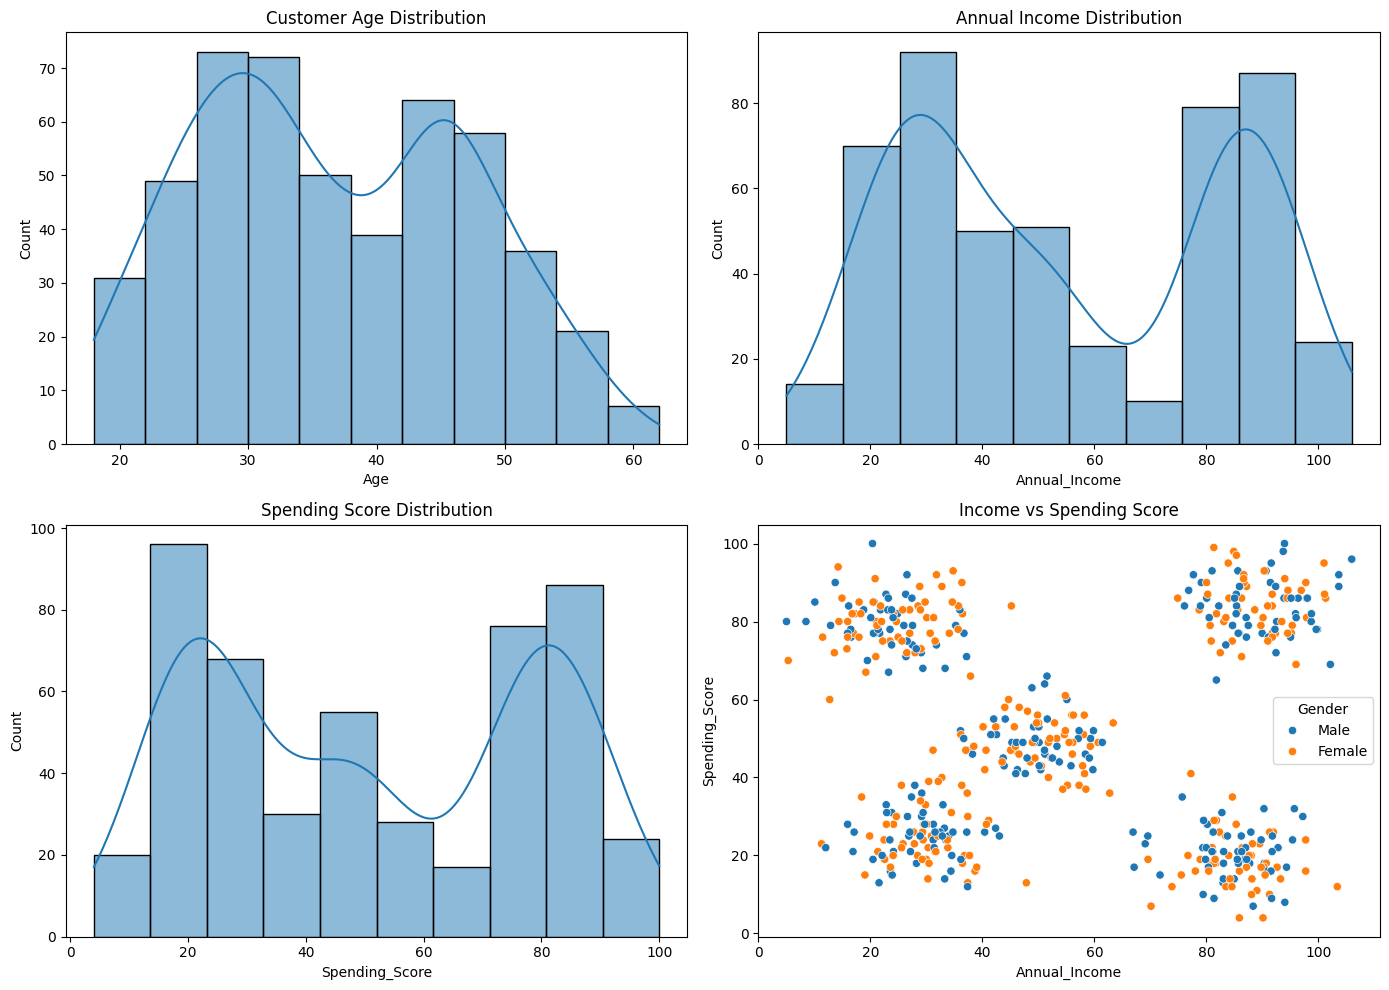


8. K-MEANS CLUSTERING GRAPH


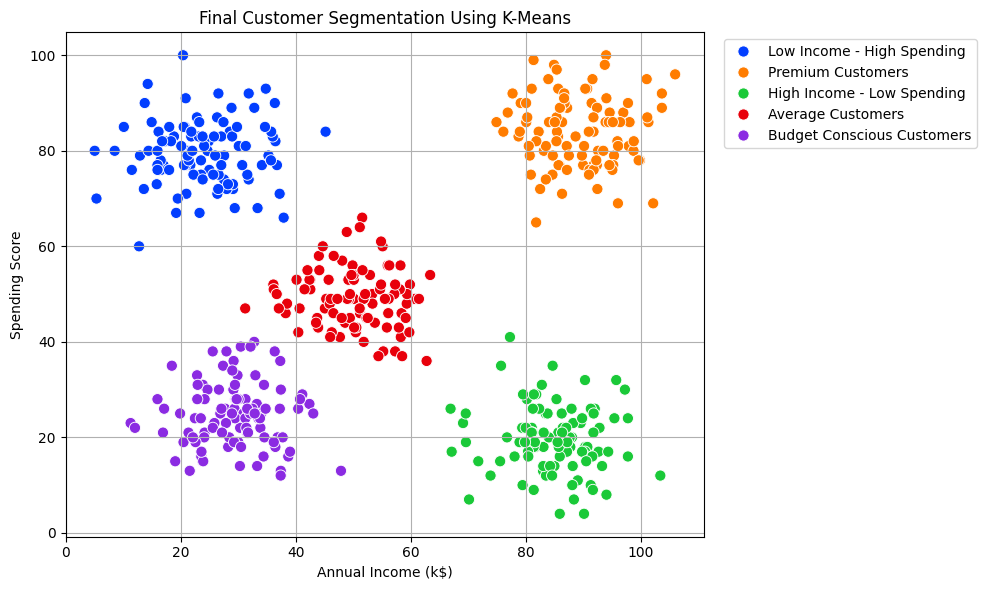


9. AVERAGE INCOME AND SPENDING COMPARISON


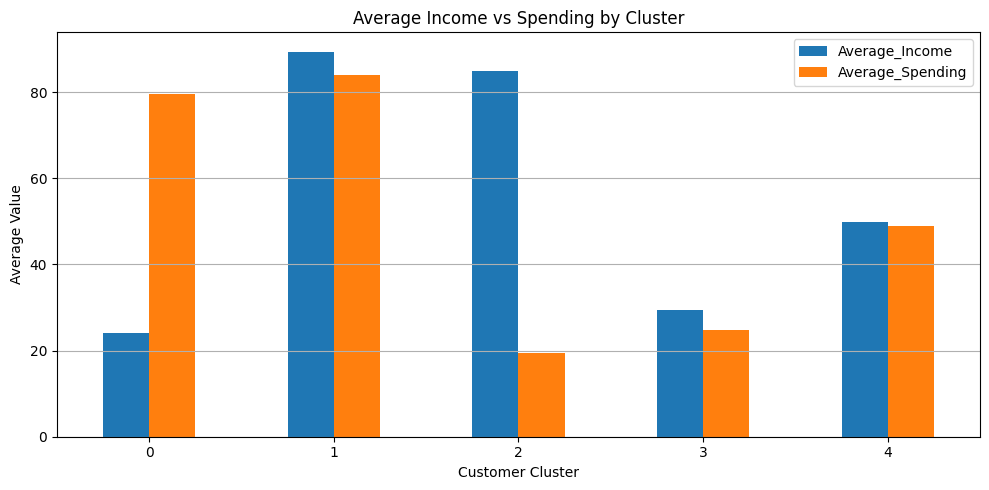


10. FINAL PROJECT CONCLUSION

The K-Means algorithm successfully segmented 500 synthetic
customer records into five different customer groups.

The model used Annual Income and Spending Score as clustering
features.

The evaluation metrics indicate good cluster separation
on this synthetic dataset.

The identified customer groups can support targeted marketing,
customer analysis and business decision-making.

       COMPLETE PROJECT RESULTS DISPLAYED SUCCESSFULLY


In [11]:

# ============================================================
# CUSTOMER SEGMENTATION USING K-MEANS
# COMPLETE PROJECT RESULTS DASHBOARD
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load final dataset
df = pd.read_csv("/content/final_customer_segmentation.csv")

# ---------------- 1. PROJECT OVERVIEW ----------------

print("=" * 65)
print("       CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING")
print("=" * 65)

print("\n1. DATASET OVERVIEW")
print("Total Customers:", len(df))
print("Total Features:", 5)
print("Algorithm: K-Means Clustering")
print("Optimal Number of Clusters: 5")

print("\n2. DATASET PREVIEW")
display(df.head(10))

print("\n3. DATA QUALITY")
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

# ---------------- 2. EVALUATION METRICS ----------------

print("\n4. MODEL EVALUATION")

evaluation = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Score"
    ],
    "Value": [
        silhouette,
        davies,
        calinski
    ]
})

display(evaluation)

# ---------------- 3. CLUSTER PROFILES ----------------

print("\n5. CUSTOMER CLUSTER PROFILES")

cluster_analysis = df.groupby("Cluster").agg({
    "CustomerID": "count",
    "Age": "mean",
    "Annual_Income": "mean",
    "Spending_Score": "mean"
}).round(2)

cluster_analysis.columns = [
    "Customer_Count",
    "Average_Age",
    "Average_Income",
    "Average_Spending"
]

display(cluster_analysis)

# ---------------- 4. SEGMENT DISTRIBUTION ----------------

print("\n6. CUSTOMER SEGMENT DISTRIBUTION")

segment_counts = df["Customer_Segment"].value_counts()
display(segment_counts.to_frame("Number_of_Customers"))

# ---------------- 5. EDA VISUALIZATIONS ----------------

print("\n7. EXPLORATORY DATA ANALYSIS GRAPHS")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df["Age"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Customer Age Distribution")

sns.histplot(df["Annual_Income"], kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Annual Income Distribution")

sns.histplot(df["Spending_Score"], kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Spending Score Distribution")

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Gender",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Income vs Spending Score")

plt.tight_layout()
plt.show()

# ---------------- 6. CLUSTER VISUALIZATION ----------------

print("\n8. K-MEANS CLUSTERING GRAPH")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Customer_Segment",
    palette="bright",
    s=65
)

plt.title("Final Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

# ---------------- 7. CLUSTER COMPARISON ----------------

print("\n9. AVERAGE INCOME AND SPENDING COMPARISON")

cluster_analysis[
    ["Average_Income", "Average_Spending"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Income vs Spending by Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ---------------- 8. FINAL CONCLUSION ----------------

print("\n10. FINAL PROJECT CONCLUSION")

print("""
The K-Means algorithm successfully segmented 500 synthetic
customer records into five different customer groups.

The model used Annual Income and Spending Score as clustering
features.

The evaluation metrics indicate good cluster separation
on this synthetic dataset.

The identified customer groups can support targeted marketing,
customer analysis and business decision-making.
""")

# ---------------- 9. SAVE FINAL REPORT DATA ----------------

df.to_csv("/content/complete_customer_results.csv", index=False)
cluster_analysis.to_csv("/content/final_cluster_profiles.csv")

print("=" * 65)
print("       COMPLETE PROJECT RESULTS DISPLAYED SUCCESSFULLY")
print("=" * 65)
